# 6. Pemetaan Pasar ke Batas Wilayah
Mencocokkan koordinat tiap pasar ke batas provinsi dan kab/kota (GADM 4.1) memakai GeoJSON yang sudah ada di `data/geo/` (point-in-polygon), lalu menyimpan tabel pasar ke wilayah untuk dashboard. Pasar kota pesisir yang titiknya sedikit di luar poligon dicocokkan ke poligon terdekat.

In [5]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_path = '../data/processed/data_bersih.csv'
prov_path = '../data/geo/provinsi.geojson'
kab_path = '../data/geo/kabkota.geojson'
output_dir = '../data/processed'
KOL_PASAR = 'mkt_name'
KOL_TANGGAL = 'date'
KOL_PROVINSI = 'adm1_name'
KOL_KABUPATEN = 'adm2_name'

In [6]:
def titik_di_cincin(x, y, cincin):
    c = np.asarray(cincin)
    x1, y1, x2, y2 = c[:-1, 0], c[:-1, 1], c[1:, 0], c[1:, 1]
    silang = ((y1 > y) != (y2 > y)) & (x < (x2 - x1) * (y - y1) / (y2 - y1 + 1e-12) + x1)
    return int(silang.sum()) % 2 == 1


def daftar_poligon(geometri):
    return [geometri['coordinates']] if geometri['type'] == 'Polygon' else geometri['coordinates']


def cari_poligon(fitur, x, y):
    for i, f in enumerate(fitur):
        for poligon in daftar_poligon(f['geometry']):
            luar = np.asarray(poligon[0])
            if x < luar[:, 0].min() or x > luar[:, 0].max() or y < luar[:, 1].min() or y > luar[:, 1].max():
                continue
            if titik_di_cincin(x, y, poligon[0]) and not any(titik_di_cincin(x, y, lubang) for lubang in poligon[1:]):
                return i
    return -1


def poligon_terdekat(fitur, x, y):
    terbaik = (-1, np.inf)
    for i, f in enumerate(fitur):
        for poligon in daftar_poligon(f['geometry']):
            luar = np.asarray(poligon[0])
            if x < luar[:, 0].min() - 0.5 or x > luar[:, 0].max() + 0.5 or y < luar[:, 1].min() - 0.5 or y > luar[:, 1].max() + 0.5:
                continue
            jarak = np.hypot((luar[:, 0] - x) * np.cos(np.radians(y)), luar[:, 1] - y).min() * 111.0
            if jarak < terbaik[1]:
                terbaik = (i, jarak)
    return terbaik


def petakan_pasar(pasar, fitur_kab, jarak_maks_km=10):
    baris = []
    for nama, lat, lon in zip(pasar[KOL_PASAR], pasar['lat'], pasar['lon']):
        i = cari_poligon(fitur_kab, lon, lat)
        metode, jarak = 'di dalam poligon', 0.0
        if i < 0:
            i, jarak = poligon_terdekat(fitur_kab, lon, lat)
            metode = 'poligon terdekat' if jarak <= jarak_maks_km else 'tidak terpetakan'
        ada = i >= 0 and metode != 'tidak terpetakan'
        prop = fitur_kab[i]['properties'] if ada else {}
        baris.append({KOL_PASAR: nama, 'gid_1': prop.get('gid_1'), 'gid_2': prop.get('id'),
                      'metode_pemetaan': metode, 'jarak_km': round(jarak, 2) if ada else np.nan})
    return pd.DataFrame(baris)

## Baca batas wilayah dan data pasar

In [7]:
fitur_prov = json.load(open(prov_path))['features']
fitur_kab = json.load(open(kab_path))['features']
print(f'Provinsi: {len(fitur_prov)} | Kab/kota: {len(fitur_kab)}')
df = pd.read_csv(data_path, parse_dates=[KOL_TANGGAL])
pasar = df.drop_duplicates(KOL_PASAR)[[KOL_PASAR, KOL_PROVINSI, KOL_KABUPATEN, 'lat', 'lon']].reset_index(drop=True)
print(f'Pasar unik: {len(pasar)} | provinsi di data: {pasar[KOL_PROVINSI].nunique()} | kab/kota di data: {pasar[KOL_KABUPATEN].nunique()}')

Provinsi: 34 | Kab/kota: 498
Pasar unik: 222 | provinsi di data: 34 | kab/kota di data: 111


## Spatial join pasar ke poligon kab/kota
Pasar dicocokkan lewat koordinat, bukan nama, karena penulisan nama di data dan di GADM berbeda.

In [8]:
peta = petakan_pasar(pasar, fitur_kab)
print(peta['metode_pemetaan'].value_counts().to_string())
print(f'Jarak poligon terdekat: maksimum {peta.loc[peta["metode_pemetaan"] == "poligon terdekat", "jarak_km"].max()} km')

metode_pemetaan
di dalam poligon    206
poligon terdekat     16
Jarak poligon terdekat: maksimum 0.77 km


In [9]:
info_kab = {f['properties']['id']: f['properties'] for f in fitur_kab}
info_prov = {f['properties']['id']: f['properties']['nama'] for f in fitur_prov}
peta['nama_kab_kota'] = peta['gid_2'].map(lambda g: info_kab[g]['nama'] if g in info_kab else None)
peta['nama_provinsi'] = peta['gid_1'].map(info_prov)
hasil = pasar.merge(peta, on=KOL_PASAR)
print(f'Pasar terpetakan: {hasil["gid_2"].notna().sum()} dari {len(hasil)}')
print(f'Kab/kota yang punya data: {hasil["gid_2"].nunique()} dari {len(fitur_kab)} ({hasil["gid_2"].nunique() / len(fitur_kab):.0%})')
print(f'Provinsi yang punya data: {hasil["gid_1"].nunique()} dari {len(fitur_prov)}')

Pasar terpetakan: 222 dari 222
Kab/kota yang punya data: 111 dari 498 (22%)
Provinsi yang punya data: 34 dari 34


## Cek konsistensi nama dengan data sumber

In [10]:
def norm(teks):
    return re.sub(r'[^a-z]', '', str(teks).lower().replace('kota', '').replace('kabupaten', '').replace('kab.', ''))

beda_kab = hasil[hasil[KOL_KABUPATEN].map(norm) != hasil['nama_kab_kota'].map(norm)]
print(f'Pasar dengan nama kab/kota di data berbeda dari poligon hasil koordinat: {len(beda_kab)}')
beda_kab[[KOL_PASAR, KOL_KABUPATEN, 'nama_kab_kota']]

Pasar dengan nama kab/kota di data berbeda dari poligon hasil koordinat: 1


,mkt_name,adm2_name,nama_kab_kota
77,Pasar Jatinegara,KOTA JAKARTA TIMUR,Kota Jakarta Selatan


Selisih nama yang tersisa umumnya hanya beda penulisan (misalnya Kab. atau Kota di depan nama). Pasar yang benar-benar berbeda wilayah menunjukkan salah label di data sumber, dan peta mengikuti koordinat.

## Visualisasi

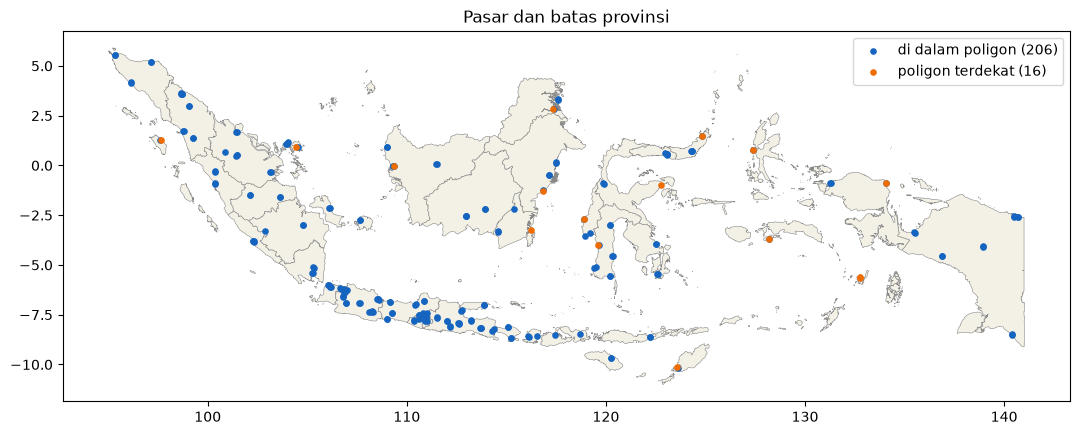

In [11]:
fig, ax = plt.subplots(figsize=(13, 6))
for f in fitur_prov:
    for poligon in daftar_poligon(f['geometry']):
        luar = np.asarray(poligon[0])
        ax.fill(luar[:, 0], luar[:, 1], facecolor='#f3f0e6', edgecolor='#888888', linewidth=0.4)
warna = {'di dalam poligon': '#1565c0', 'poligon terdekat': '#ef6c00', 'tidak terpetakan': '#c62828'}
for metode, g in hasil.groupby('metode_pemetaan'):
    ax.scatter(g['lon'], g['lat'], s=14, color=warna[metode], label=f'{metode} ({len(g)})', zorder=3)
ax.set_aspect('equal')
ax.legend()
ax.set_title('Pasar dan batas provinsi')
plt.show()

## Simpan hasil

In [12]:
kolom = [KOL_PASAR, 'gid_1', 'gid_2', 'nama_provinsi', 'nama_kab_kota', 'metode_pemetaan', 'jarak_km']
hasil[kolom].to_csv(f'{output_dir}/pasar_wilayah.csv', index=False)
print('pasar_wilayah.csv tersimpan di', output_dir)

pasar_wilayah.csv tersimpan di ../data/processed
